<a href="https://colab.research.google.com/github/Jacquou2/Data_mining_project/blob/main/IR_Plots.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#import plotly.plotly as py
from plotly.offline import init_notebook_mode, iplot
init_notebook_mode(connected=True)
import plotly.graph_objs as go

import seaborn as sns
from scipy import stats
from scipy.stats import norm
from scipy.stats import spearmanr
#so we dont have to write .plot()
%matplotlib inline
sns.set_style("whitegrid") #possible choices: white, dark, whitegrid, darkgrid, ticks
train = pd.read_csv('train.csv', sep=',')
test = pd.read_csv('test.csv', sep=',')

In [ ]:
train.head()

,obs_id,Center Lat,Center Long,Overall Probability,distanceToCoast,majorRiverDistance,majorRiversScale,bathymetry,substrateType,temperatureSurface_mean,...,nitrate100_300_neighbor_min,nitrate100_300_neighbor_std,phosphateSurface_neighbor_mean,phosphateSurface_neighbor_max,phosphateSurface_neighbor_min,phosphateSurface_neighbor_std,phosphate100_300_neighbor_mean,phosphate100_300_neighbor_max,phosphate100_300_neighbor_min,phosphate100_300_neighbor_std
0,0,37.25,15.25,0.78,0.202705,405.785399,9,-20.975300,Muddy sand,20.342262,...,0.105786,0.863075,0.015962,0.021693,0.013084,0.003389,0.083518,0.139495,0.022677,0.048012
1,1,38.25,1.25,0.28,45.173330,358.080457,5,-1380.840000,Sand,19.975585,...,3.911926,0.415026,0.012160,0.013913,0.011261,0.001031,0.258413,0.263190,0.245935,0.007244
2,2,36.75,5.25,1.00,11.082162,707.703993,9,-772.565979,Sandy mud,20.033488,...,4.285709,0.000000,0.018645,0.018645,0.018645,0.000000,0.247956,0.247956,0.247956,0.000000
3,3,36.25,11.25,1.00,45.638871,616.947859,9,-68.390900,Fine mud,20.512575,...,0.081863,0.274042,0.013061,0.018203,0.009727,0.002953,0.021216,0.080217,0.009735,0.022483
4,4,35.25,32.25,0.06,15.474774,379.020110,6,-1582.170000,Unknown,22.447230,...,1.021640,0.000000,0.009224,0.009224,0.009224,0.000000,0.069003,0.069003,0.069003,0.000000


## Temperature Surface Quantile Plots
Οι παρατηρήσεις temperatureSurface_quantile_1, temperatureSurface_quantile_5 και temperatureSurface_quantile_10 παραουσιάζουν παρόμοια κατανομή. Γενικά, όσο αυξάνονται αυτές οι μεταβλητές τόσο αυξάνεται και η συνολική πιθανότητα.   

/usr/local/lib/python3.7/dist-packages/seaborn/_decorators.py:43: FutureWarning:

Pass the following variables as keyword args: x, y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.

/usr/local/lib/python3.7/dist-packages/seaborn/_decorators.py:43: FutureWarning:

Pass the following variables as keyword args: x, y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.

/usr/local/lib/python3.7/dist-packages/seaborn/_decorators.py:43: FutureWarning:

Pass the following variables as keyword args: x, y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.



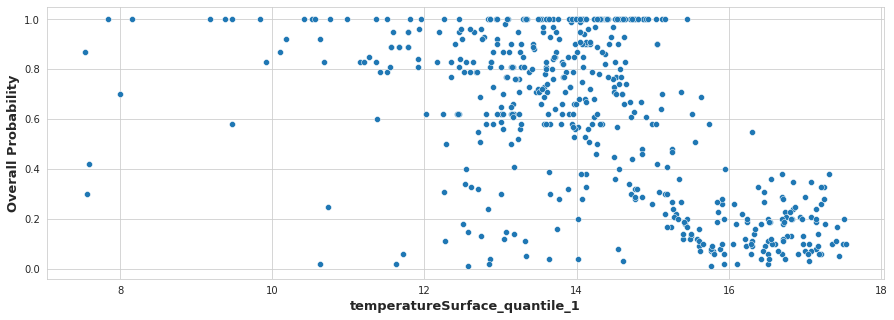

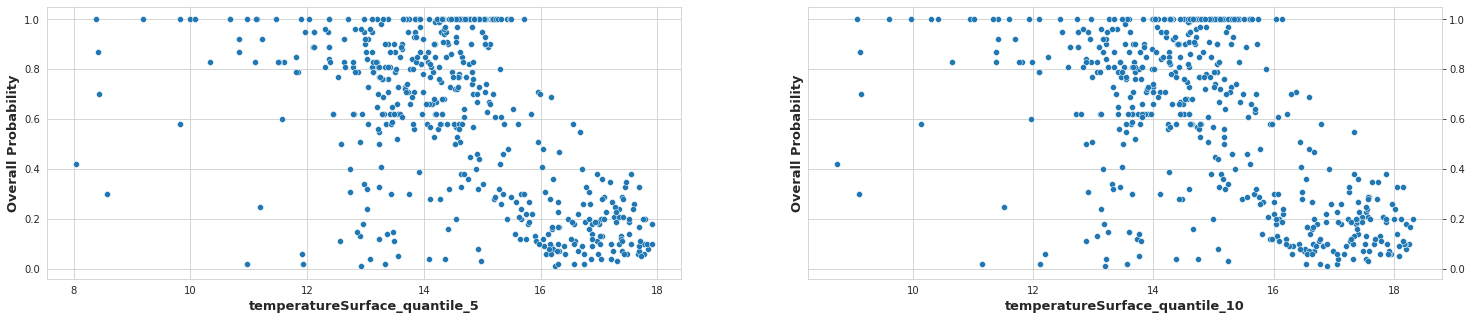

In [ ]:
fig, ax = plt.subplots(figsize=(15, 5))
sns.scatterplot(train['temperatureSurface_quantile_1'], train['Overall Probability'])





fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(25, 5))
sns.scatterplot(train['temperatureSurface_quantile_5'], train['Overall Probability'], ax=ax[0])
sns.scatterplot(train['temperatureSurface_quantile_10'], train['Overall Probability'], ax=ax[1])
ax[0].set_xlabel('temperatureSurface_quantile_5', fontsize = 13, fontdict=dict(weight='bold')); ax[0].set_ylabel('Overall Probability', fontsize = 13, fontdict=dict(weight='bold'))
ax[1].set_xlabel('temperatureSurface_quantile_10', fontsize = 13, fontdict=dict(weight='bold')); ax[1].set_ylabel('Overall Probability', fontsize = 13, fontdict=dict(weight='bold'))
ax[1].yaxis.tick_right() # where the y axis marks will be

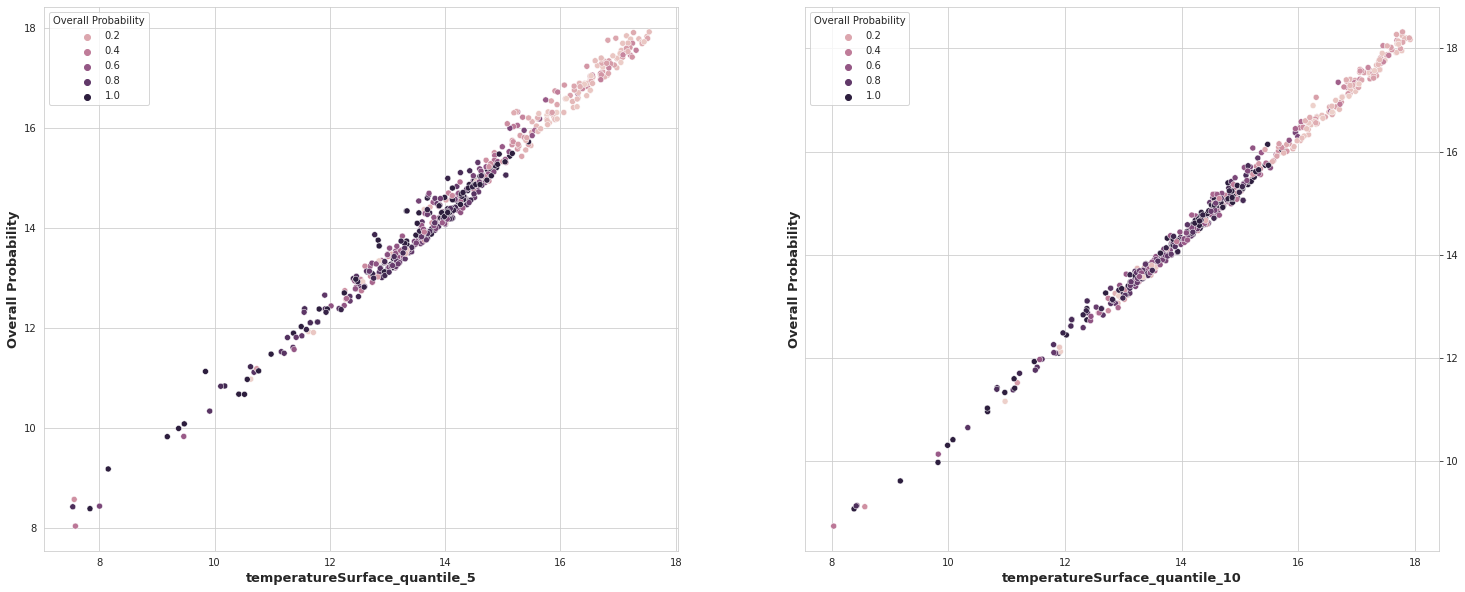

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(25, 10))
sns.scatterplot(data=train, x="temperatureSurface_quantile_1", y="temperatureSurface_quantile_5", hue="Overall Probability",ax=ax[0])
sns.scatterplot(data=train, x="temperatureSurface_quantile_5", y="temperatureSurface_quantile_10", hue="Overall Probability",ax=ax[1])
ax[0].set_xlabel('temperatureSurface_quantile_5', fontsize = 13, fontdict=dict(weight='bold')); ax[0].set_ylabel('Overall Probability', fontsize = 13, fontdict=dict(weight='bold'))
ax[1].set_xlabel('temperatureSurface_quantile_10', fontsize = 13, fontdict=dict(weight='bold')); ax[1].set_ylabel('Overall Probability', fontsize = 13, fontdict=dict(weight='bold'))
ax[1].yaxis.tick_right()

### Substrate type Plot    
Σε αυτό το διάγραμμα φαίνεται η εξαρτηση της συνολικής πιθανότητας από το υπέδαφος. Στις κατηγορίες Sand,Fine mud,Rock or other hard substrata και Cymodocea nodosa neadowns σχεδόν τα μισά δείγματα έχουν Overall Probability πάνω από 80%

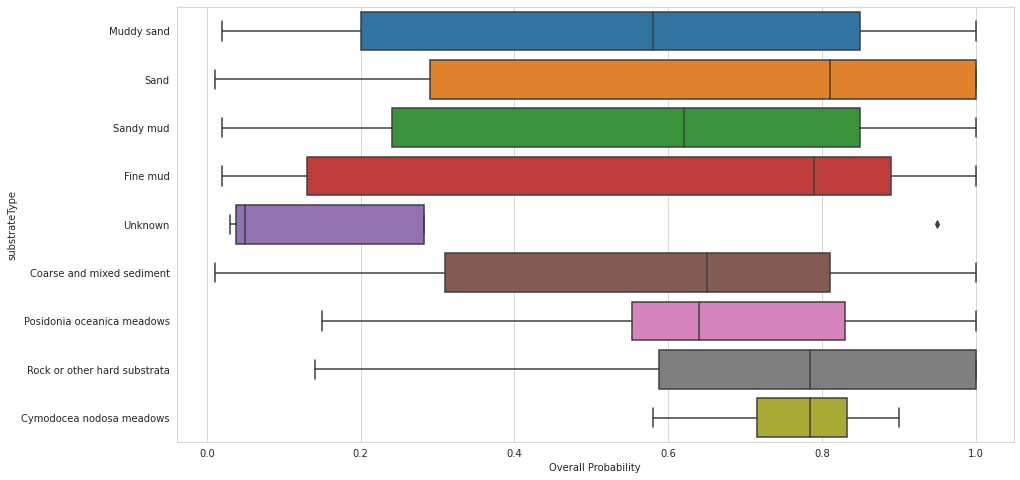

In [ ]:
fig, ax = plt.subplots(figsize=(15,8))
ax = sns.boxplot(x="Overall Probability", y="substrateType", data=train)

/usr/local/lib/python3.7/dist-packages/seaborn/_decorators.py:43: FutureWarning:

Pass the following variables as keyword args: x, y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.



Text(0, 0.5, 'Center Lat')

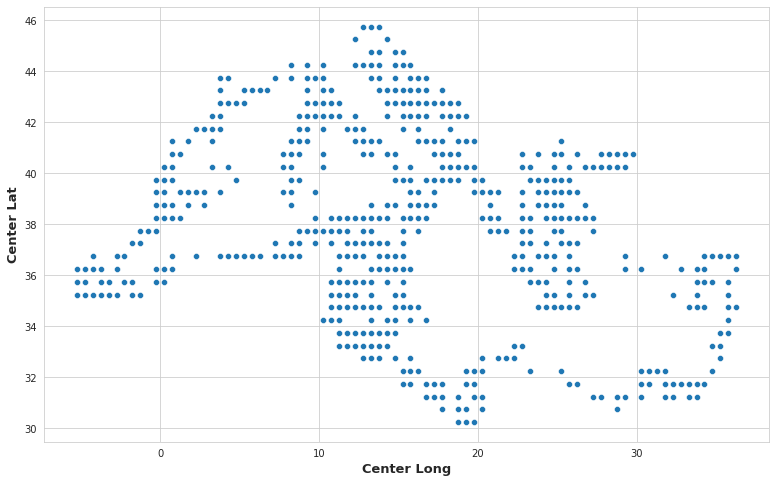

In [ ]:
# Map of the Mediterranean  #
fig, ax = plt.subplots(figsize=(13,8))
sns.scatterplot(train['Center Long'], train['Center Lat'])

ax.set_xlabel('Center Long', fontsize = 13, fontdict=dict(weight='bold'))
ax.set_ylabel('Center Lat', fontsize = 13, fontdict=dict(weight='bold'))

## Salinity Correlation Plot
Φαίνεται η σύνδεση μεταξύ όλων των μεταβλητών που σχετίζονται με την αλατότητα του νερού. Οι μεταβλητές salinitySurface mean και salinitySurface median έχουν ισχυρή συσχέτιση (είναι ανάλογες) ενώ οι μεταβλητές salinitySurface min και salinitySurface max_to_min_diff είναι αντιστρόφως ανάλογες (διαισθητικά ισχύει).

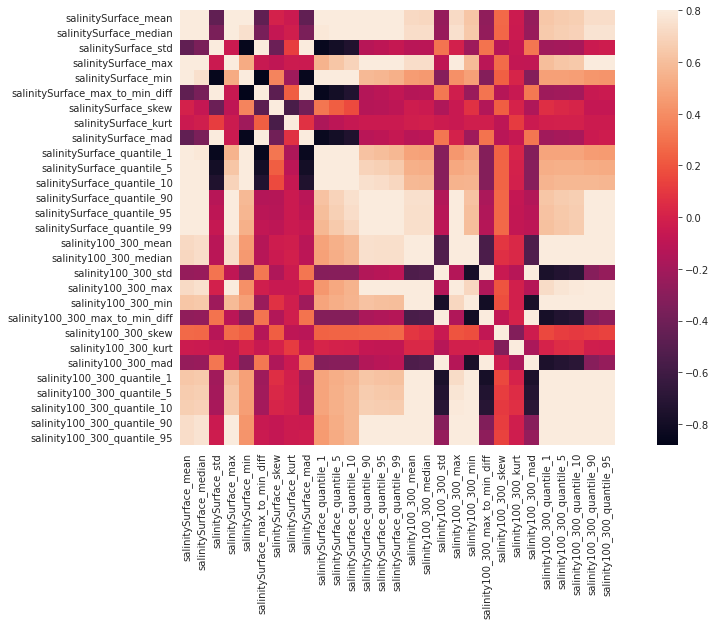

In [ ]:
salinity = train.iloc[:,[i for i in range(39,68)]]
corrmat = salinity.corr()
fig, ax = plt.subplots(figsize=(15,8))
sns.heatmap(corrmat, vmax=.8, square=True);

## Bathymetry, Major River distance and scale Plots
Τα παρακάτω διαγράμματα δείχνουν την προτίμηση στις μετρήσεις του dataset. Φαίνεται οτι οι περισσσότερες μετρήσεις έγιναν κοντά στην επιφάνεια και σε απόσταση 200 μετρων από το κοντινότερο ποτάμι. Οι περισσότερες μετρήσεις έγιναν κοντά σε ποτάμια μεγάλης κλίμακας.

/usr/local/lib/python3.7/dist-packages/seaborn/distributions.py:2619: FutureWarning:

`distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).

/usr/local/lib/python3.7/dist-packages/seaborn/distributions.py:2619: FutureWarning:

`distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).



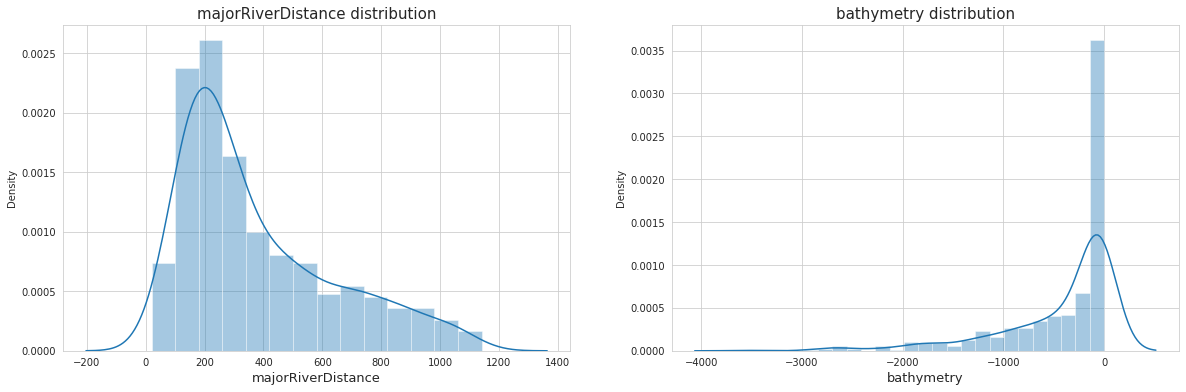

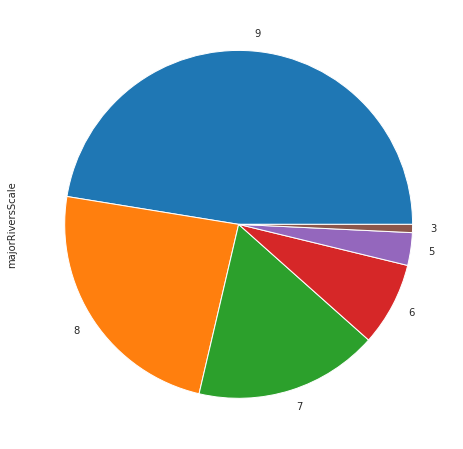

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(20, 6))

sns.distplot(train['majorRiverDistance'],  ax = ax[0])
sns.distplot(train['bathymetry'],ax = ax[1])

ax[0].set_title('majorRiverDistance distribution', fontsize = 15, loc='center')
ax[0].set_xlabel('majorRiverDistance', fontsize = 13)
ax[1].set_title('bathymetry distribution', fontsize = 15, loc='center')
ax[1].set_xlabel('bathymetry', fontsize = 13)


fig, ax = plt.subplots(figsize=(15, 8))
train['majorRiversScale'].value_counts().plot(kind='pie')

plt.tick_params(axis='x', which='major', labelsize=12)

/usr/local/lib/python3.7/dist-packages/seaborn/_decorators.py:43: FutureWarning:

Pass the following variables as keyword args: x, y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.



Text(0, 0.5, 'Overall Probability')

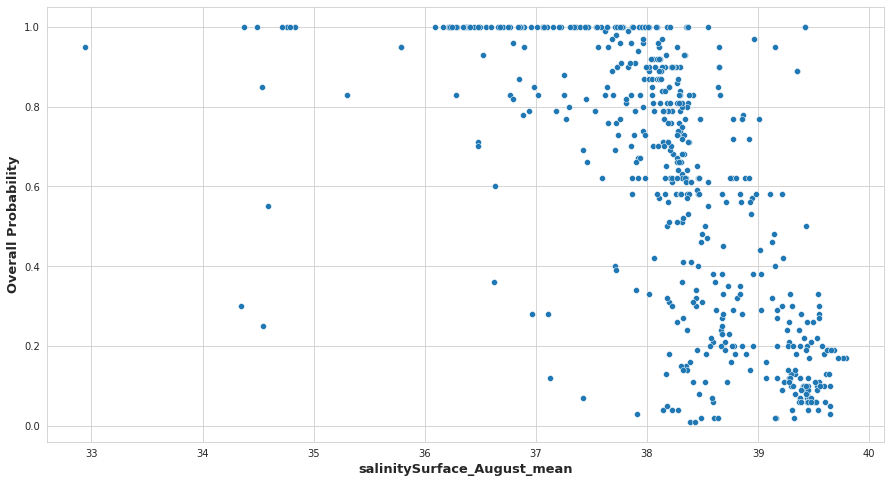

In [ ]:
fig, ax = plt.subplots(figsize=(15,8))
sns.scatterplot(train['salinitySurface_August_mean'], train['Overall Probability'])

ax.set_xlabel('salinitySurface_August_mean', fontsize = 13, fontdict=dict(weight='bold'))
ax.set_ylabel('Overall Probability', fontsize = 13, fontdict=dict(weight='bold'))